## An implementation of "An Efficiency-Boosting Client Selection Scheme for Federated Learning With Fairness Guarantee"


In [71]:
import torch
import torchvision
from torchvision.transforms import v2
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as nnFunctional

import matplotlib.pyplot as plt
import numpy as np
import random

batch_size = 64
SEED = 1234

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.backends.cudnn.deterministic = True

device = torch.device(torch.accelerator.current_accelerator()
                      .type if torch.accelerator.is_available() else 'cpu')
print(device, 'device detected')

cuda device detected


In [72]:
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)])

In [73]:
# pull MNIST data
train_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_mnist_loader = torch.utils.data.DataLoader(train_mnist, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
test_mnist = torchvision.datasets.MNIST(root='./data', train=False,
                                       download=True, transform=transform)
test_mnist_loader = torch.utils.data.DataLoader(test_mnist, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

print(f'Number of training examples: {len(train_mnist)}')
print(f'Number of testing examples: {len(test_mnist)}')

Number of training examples: 60000
Number of testing examples: 10000


In [74]:
for X, y in train_mnist_loader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

for X, y in test_mnist_loader:
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64
Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


In [75]:
# Show an image in matplotlib
def imshow(img) -> None:
    """
    :param: img - the PIL png image to show
    """
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(a=npimg, axes=(1,2,0)))
    plt.show()

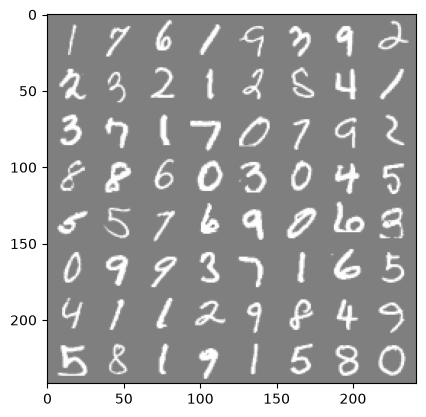

In [76]:
dataiter = iter(train_mnist_loader)
images, labels = next(dataiter)
imshow(torchvision.utils.make_grid(images))

In [108]:
def show_image(tensor):
    image = np.array(tensor, dtype='float')
    # pixels = image.reshape((28, 28))
    plt.imshow(image, cmap='gray')
    plt.show()

### MLP 2NN

In [91]:
"""
Pytorch Multi-Layer Perceptron impl with 2 layers, 200 dense each, 10 factors
"""
class MNIST_mlp2NN(nn.Module):

    def __init__(self):
        super(MNIST_mlp2NN, self).__init__()
        self.mlp = nn.Sequential(
            nn.Flatten(),
            torchvision.ops.MLP(
                in_channels=28 * 28,
                hidden_channels=[200, 200, 10],
                activation_layer=nn.ReLU,
            )
        )
        
    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits


if __name__ == "__main__":
    mlp_model = MNIST_mlp2NN()
    # show tensor output shape size
    dummy_tensor = torch.randn(1, 1, 28, 28)
    output = mlp_model.mlp(dummy_tensor)
    print(f"MNIST Output Shape: {output.shape} (Expected: [1, 10])")
    print("\nShow output of MNIST Model...")
    print('model', mlp_model.mlp)

MNIST Output Shape: torch.Size([1, 10]) (Expected: [1, 10])

Show output of MNIST Model...
model Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): MLP(
    (0): Linear(in_features=784, out_features=200, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=200, out_features=200, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=200, out_features=10, bias=True)
    (7): Dropout(p=0.0, inplace=False)
  )
)


In [92]:
# The number of parameters matches the white paper
def count_parameters(model) -> int:
    """ 
    :param: model - the ML model to count parameters for
    :return: int - total training parameters size
    """
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f'The model has {count_parameters(mlp_model.mlp):,} trainable parameters')

The model has 199,210 trainable parameters


In [93]:
# loss function instantiation 
loss_fn = nn.CrossEntropyLoss()
# The pytorch example uses SGD
optimizer = optim.SGD(mlp_model.mlp.parameters(), lr=0.001, momentum=0.9)

In [94]:
def train(dataloader, model, loss_fn, optimizer):
    """
    :param: dataloader - The pytorch data partitioner 
    :param: model - ML model (MLP)
    :param: loss_fn - loss function 
    :param: optimizer - SGD 
    """
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        # Compute prediction error
        y_pred = model(X)
        loss = loss_fn(y_pred, y)

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if batch % 100 == 0:
            loss, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

In [95]:
def test(dataloader, model, loss_fn):
    """
    :param: dataloader - The pytorch data partitioner 
    :param: model - ML model (MLP)
    :param: loss_fn - loss function 
    """
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    # use pytorch's eval, with turned off gradients for inference
    model.eval()
    test_loss, correct = 0, 0

    with torch.no_grad():
        for factors, y in dataloader:
            factors, y = factors, y
            pred = model(factors)
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

In [96]:
epochs = 5
for round in range(epochs):
    print(f"Epoch {round+1}\n-------------------------------")
    train(dataloader=train_mnist_loader, model=mlp_model.mlp, loss_fn=loss_fn, optimizer=optimizer)

print('Finished MNIST Training')
SAVED_MODEL = './mnist_mlp.pt'
torch.save(mlp_model.state_dict(), SAVED_MODEL)
print("saved mlp model.pt")

Epoch 1
-------------------------------
loss: 2.308600  [   64/60000]
loss: 2.276652  [ 6464/60000]
loss: 2.228812  [12864/60000]
loss: 2.145862  [19264/60000]
loss: 1.988423  [25664/60000]
loss: 1.706177  [32064/60000]
loss: 1.422483  [38464/60000]
loss: 1.271999  [44864/60000]
loss: 0.969306  [51264/60000]
loss: 0.887459  [57664/60000]
Epoch 2
-------------------------------
loss: 0.909145  [   64/60000]
loss: 0.639206  [ 6464/60000]
loss: 0.604028  [12864/60000]
loss: 0.587335  [19264/60000]
loss: 0.357327  [25664/60000]
loss: 0.566743  [32064/60000]
loss: 0.485448  [38464/60000]
loss: 0.563460  [44864/60000]
loss: 0.362669  [51264/60000]
loss: 0.499258  [57664/60000]
Epoch 3
-------------------------------
loss: 0.314916  [   64/60000]
loss: 0.528684  [ 6464/60000]
loss: 0.395476  [12864/60000]
loss: 0.257769  [19264/60000]
loss: 0.273545  [25664/60000]
loss: 0.496790  [32064/60000]
loss: 0.314362  [38464/60000]
loss: 0.415339  [44864/60000]
loss: 0.339481  [51264/60000]
loss: 0.32

In [97]:
test(dataloader=test_mnist_loader, model=mlp_model.mlp, loss_fn=loss_fn)

Test Error: 
 Accuracy: 91.8%, Avg loss: 0.286385 



In [98]:
classes = [
    "0",
    "1",
    "2",
    "3",
    "4",
    "5",
    "6",
    "7",
    "8",
    "9",
]

mlp_model.mlp.eval()
with torch.no_grad():
    # test first output from test set
    pred = mlp_model.mlp(test_mnist[0][0])
    predicted, actual = classes[pred[0].argmax(0)], classes[test_mnist[0][1]]
    print(f'Predicted: "{predicted}", Actual: "{actual}"')

Predicted: "7", Actual: "7"


## CNN MNIST 

In [41]:
# clear device state from previous run
device = torch.device(torch.accelerator.current_accelerator()
                      .type if torch.accelerator.is_available() else 'cpu')
print(device, 'device detected')

batch_size = 64

transform = v2.Compose([
    v2.Resize((40, 40)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)])

cuda device detected


In [42]:
train_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_mnist_loader = torch.utils.data.DataLoader(train_mnist, batch_size=batch_size,
                                          shuffle=True, num_workers=2)
test_mnist = torchvision.datasets.MNIST(root='./data', train=False,
                                       download=True, transform=transform)
test_mnist_loader = torch.utils.data.DataLoader(test_mnist, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

In [43]:
class CNN_mnist(nn.Module):

    def __init__(self):
        super(CNN_mnist, self).__init__()
        # 2 CNN models with 2 5x5 layers, each with 32 and then 64 channels
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=32, kernel_size=5)
        self.conv2 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=5)
        # 2x2 max pool
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.fc1 = nn.Linear(64 * 7 * 7, 512)
        self.fc2 = nn.Linear(512, 10)
        

    def forward(self, tensor):
        # flatten images except batch
        tensor = self.pool(nnFunctional.relu(self.conv1(tensor)))
        tensor = self.pool(nnFunctional.relu(self.conv2(tensor)))
        tensor = torch.flatten(tensor, 1)
        # apply relu function to network
        tensor = nnFunctional.relu(self.fc1(tensor))
        return self.fc2(tensor)


if __name__ == "__main__":
    cnn_model = CNN_mnist()
    # test input
    dummy_image = torch.randn(1, 1, 40, 40)
    c_output = cnn_model(dummy_image)
    print(f"MNIST Output Shape: {c_output.shape} (Expected: [1, 10])")

MNIST Output Shape: torch.Size([1, 10]) (Expected: [1, 10])


In [44]:
print(f'The model has {count_parameters(cnn_model):,} trainable parameters')

The model has 1,663,370 trainable parameters


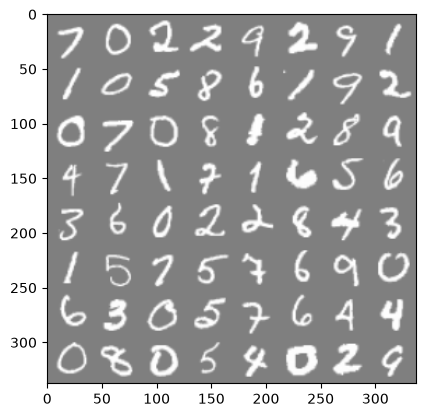

7     0     2     2     9     2     9     1     1     0     5     8     6     1     9     2     0     7     0     8     1     2     8     9     4     7     1     7     1     6     5     6     3     6     0     2     2     8     4     3     1     5     7     5     7     6     9     0     6     3     0     5     7     6     4     4     0     8     0     5     4     0     2     9    


In [45]:
mnist_dataiter = iter(train_mnist_loader)
images, labels = next(mnist_dataiter)

imshow(torchvision.utils.make_grid(images))
print(' '.join(f'{classes[labels[j]]:5s}' for j in range(batch_size)))

In [46]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(cnn_model.parameters(), lr=0.001, momentum=0.9)

In [47]:
epochs = 5
for round in range(epochs):
    print(f"Epoch {round+1}\n-------------------------------")
    running_loss = 0.0

    for iter_train_set, data in enumerate(train_mnist_loader, 0):

        inputs, labels = data[0], data[1]
        # dont use parameter gradients
        optimizer.zero_grad()

        # forward + backward + optimize
        outputs = cnn_model(inputs)
        # cnn_labels = cnn_model(labels)
        
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()
        
        if iter_train_set % 10 == 9:
            print(f'[{round + 1}, {iter_train_set + 1:5d}] loss: {running_loss / 10:.3f}')
            running_loss = 0.0

print('Finished Training')
SAVED_MODEL = './mnist_cnn.pt'
torch.save(cnn_model.state_dict(), SAVED_MODEL)
print("saved mnist_cnn.pt")

Epoch 1
-------------------------------
[1,    10] loss: 2.304
[1,    20] loss: 2.301
[1,    30] loss: 2.295
[1,    40] loss: 2.291
[1,    50] loss: 2.285
[1,    60] loss: 2.282
[1,    70] loss: 2.275
[1,    80] loss: 2.269
[1,    90] loss: 2.262
[1,   100] loss: 2.258
[1,   110] loss: 2.245
[1,   120] loss: 2.238
[1,   130] loss: 2.221
[1,   140] loss: 2.210
[1,   150] loss: 2.185
[1,   160] loss: 2.164
[1,   170] loss: 2.131
[1,   180] loss: 2.093
[1,   190] loss: 2.054
[1,   200] loss: 1.982
[1,   210] loss: 1.906
[1,   220] loss: 1.795
[1,   230] loss: 1.678
[1,   240] loss: 1.508
[1,   250] loss: 1.327
[1,   260] loss: 1.097
[1,   270] loss: 0.964
[1,   280] loss: 0.828
[1,   290] loss: 0.748
[1,   300] loss: 0.674
[1,   310] loss: 0.659
[1,   320] loss: 0.574
[1,   330] loss: 0.592
[1,   340] loss: 0.467
[1,   350] loss: 0.480
[1,   360] loss: 0.461
[1,   370] loss: 0.510
[1,   380] loss: 0.467
[1,   390] loss: 0.479
[1,   400] loss: 0.453
[1,   410] loss: 0.497
[1,   420] loss: 

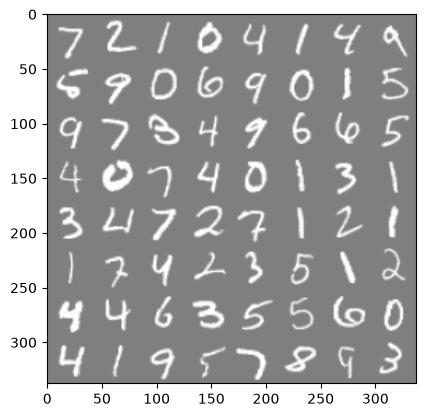

Truth  7     2     1     0    


In [48]:
dataiter = iter(test_mnist_loader)
images, labels = next(dataiter)

imshow(torchvision.utils.make_grid(images))
print('Truth ', ' '.join(f'{classes[labels[j]]:5s}' for j in range(4)))

In [49]:
cnn_model = CNN_mnist()
cnn_model.load_state_dict(torch.load(SAVED_MODEL, weights_only=True))

<All keys matched successfully>

In [50]:
outputs = cnn_model(images) 
_, predicted = torch.max(outputs, 1)
print('Predicted ', ''.join(f'{classes[predicted[j]]:5s}' for j in range(4)))

Predicted  7    2    1    0    


In [51]:
correct = 0
total = 0
# since we're not training, we don't need to calculate the gradients for our outputs
with torch.no_grad():
    for data in test_mnist_loader:
        images, labels = data
        output = cnn_model(images)
        # the class with the highest energy is what we choose as prediction
        _, predicted = torch.max(output, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f'Accuracy of the network on the 10000 test images: {100 * correct // total} %')

Accuracy of the network on the 10000 test images: 97 %


In [52]:
# prepare to count predictions for each class
correct_pred = {classname: 0 for classname in classes}
total_pred = {classname: 0 for classname in classes}

# again no gradients needed
with torch.no_grad():
    for data in test_mnist_loader:
        images, labels = data
        outputs = cnn_model(images).to(device)
        _, predictions = torch.max(outputs, 1)
        # collect the correct predictions for each class
        for label, prediction in zip(labels, predictions):
            if label == prediction:
                correct_pred[classes[label]] += 1
            total_pred[classes[label]] += 1


# print accuracy for each class
for classname, correct_count in correct_pred.items():
    accuracy = 100 * float(correct_count) / total_pred[classname]
    print(f'Accuracy for class: {classname:5s} is {accuracy:.1f} %')

Accuracy for class: 0     is 99.2 %
Accuracy for class: 1     is 99.4 %
Accuracy for class: 2     is 98.9 %
Accuracy for class: 3     is 96.8 %
Accuracy for class: 4     is 98.1 %
Accuracy for class: 5     is 98.3 %
Accuracy for class: 6     is 97.9 %
Accuracy for class: 7     is 97.4 %
Accuracy for class: 8     is 98.2 %
Accuracy for class: 9     is 95.3 %


# MNIST IID

In [53]:

transform = v2.Compose([
    v2.Resize((40, 40)),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)])

batch_size = 600
train_mnist = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_mnist_loader = torch.utils.data.DataLoader(train_mnist, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

test_mnist = torchvision.datasets.MNIST(root='./data', train=False,
                                       download=True, transform=transform)
test_mnist_loader = torch.utils.data.DataLoader(test_mnist, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

print(f'Number of training examples: {len(train_mnist)}')
print(f'Number of testing examples: {len(test_mnist)}')
print(f'Number of train dataloader examples: {len(train_mnist_loader)}')
print(f'Number of test dataloader examples: {len(test_mnist_loader)}')

Number of training examples: 60000
Number of testing examples: 10000
Number of train dataloader examples: 100
Number of test dataloader examples: 17


In [54]:
print(train_mnist_loader.dataset)

Dataset MNIST
    Number of datapoints: 60000
    Root location: ./data
    Split: Train
    StandardTransform
Transform: Compose(
                 Resize(size=[40, 40], interpolation=bilinear, antialias=True)
                 ToImage()
                 ToDtype(scale=True)
           )


In [85]:
for X, y in train_mnist_loader:
    print(X,y)
    break

tensor([[[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.]]],


        ...,


        [[[0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          [0., 0., 0.,  ..., 0., 0., 0.],
          ...,
          [0., 0., 0.,  ..., 0.

In [87]:
for X, y in train_mnist_loader:
    print(f"default shape of X [N, C, H, W]: {X.shape}")
    print(f"default shape of y: {y.shape} {y.dtype}")
    break


default shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
default shape of y: torch.Size([64]) torch.int64


In [ ]:

def select_random_clients(dict_clients, num_clients, dataset, samples) -> dict:
    """
    Partition IID client data from MNIST dataset.
    Random draw with replacement.
    :param num_clients: number of clients to split on.
    :param dataset: train_mnist - the training set
    :return dict of partitioned images and indexes 
    """
    for client in range(num_clients): 
        sample = random.choices(population=list(dataset),k=samples)
        dict_clients[client] = sample    
    return dict_clients

dict_clients = dict()
num_total_clients = 100
dict_clients = select_random_clients(dict_clients=dict_clients, num_clients=num_total_clients, dataset=train_mnist.data, samples=600)



In [101]:
print(dict_clients[0])

[tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,  43,  43,  43,  43, 219,
         254, 252, 252, 252, 252, 254, 252, 252, 252,  41,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,  

In [ ]:
# select a fraction of clients
global_batch_size_clients = [0, .1, .2, .5, 1]

# load mlp model
global_model = MNIST_mlp2NN()
global_model.load_state_dict(torch.load('./mnist_mlp.pt', weights_only=True))

# Print model's state_dict
print("Model's state_dict:")
for param_tensor in global_model.state_dict():
    print(param_tensor, "\t", global_model.state_dict()[param_tensor].size())

Model's state_dict:
mlp.1.0.weight 	 torch.Size([200, 784])
mlp.1.0.bias 	 torch.Size([200])
mlp.1.3.weight 	 torch.Size([200, 200])
mlp.1.3.bias 	 torch.Size([200])
mlp.1.6.weight 	 torch.Size([10, 200])
mlp.1.6.bias 	 torch.Size([10])


In [ ]:
def FedAvg(model, local_epoch, local_batch_size):
    """ 
    :param: model: the global model state.
    :param: local_epoch: the number of local rounds to complete. 
    """
    local_model = 0
    for epoch in range(local_epoch):
        for batch in range(local_batch_size):
            pass
    return local_model.state_dict()


/tmp/ipykernel_55220/4173761358.py:2: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  image = np.array(tensor, dtype='float')


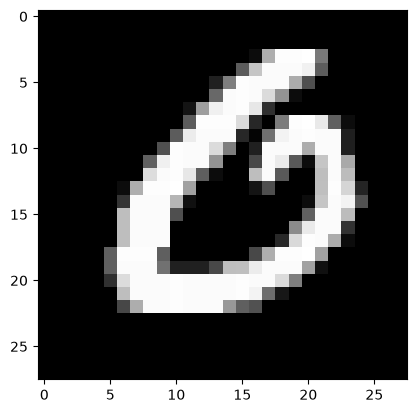

In [111]:
#TODO initalize local weights, global weights, local_loss, global_loss, etc

global_weights = []
global_loss = 0
learning_rate = 0.1 

# global rounds
for epoch in range(20):
    local_epoch = 20
    local_loss = 0
    local_weights = []
    local_batch_size = 50

    for client in global_batch_size_clients:
        m = max((client * num_total_clients), 1)
        #TODO get clients by index'd m 
        random_clients = random.choices(population=dict_clients, k=m)
        show_image(random_clients[0][0])
        break
        #client_updates = train(train_mnist_loader, global_model, loss_fn=loss_fn, optimizer=optimizer)
        #local_weights.append(client_updates)
        #new_global_weights = FedAvg(local_weights, local_epoch=local_epoch, local_batch_size=local_batch_size)

    break